# Diabetes Health Indicators

BRFSS 2021 binary classification: Diabetes_binary (0 = no diabetes/prediabetes, 1 = diabetes).

Steps: EDA → balance the training data → XGBoost vs. Logistic Regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = "Diabetes_binary"
pd.set_option("display.max_columns", None)

## 1. Load data
Columns are stored as floats, so they are cast to `int`.

In [2]:
df = pd.read_csv('diabetes_binary_BRFSS2021_cleaned.csv').astype(int)
print("Original shape:", df.shape)
display(df.head())

Original shape: (223243, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,15,1,0,0,0,1,1,0,1,0,5,10,20,0,0,11,4,5
1,1,1,0,1,28,0,0,1,0,1,0,0,1,0,2,0,0,0,0,11,4,3
2,1,1,1,1,33,0,0,0,1,1,1,0,1,0,2,10,0,0,0,9,4,7
3,1,0,1,1,29,0,1,1,1,1,1,0,1,0,5,0,30,1,1,12,3,4
4,0,0,0,1,24,1,0,0,0,0,0,0,1,0,3,0,0,1,1,13,5,6


## 2. Data quality

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Missing values: 0
Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,223243.0,0.149590,0.356670,0.0,0.0,0.0,0.0,1.0
HighBP,223243.0,0.431642,0.495306,0.0,0.0,0.0,1.0,1.0
HighChol,223243.0,0.410812,0.491982,0.0,0.0,0.0,1.0,1.0
CholCheck,223243.0,0.961450,0.192520,0.0,1.0,1.0,1.0,1.0
BMI,223243.0,29.134414,6.646068,12.0,25.0,28.0,32.0,99.0
Smoker,223243.0,0.426213,0.494527,0.0,0.0,0.0,1.0,1.0
Stroke,223243.0,0.041175,0.198695,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,223243.0,0.091174,0.287857,0.0,0.0,0.0,0.0,1.0
PhysActivity,223243.0,0.766864,0.422829,0.0,1.0,1.0,1.0,1.0
Fruits,223243.0,0.607643,0.488277,0.0,0.0,1.0,1.0,1.0


No missing values. 13,135 exact duplicates (5.6%), removed so the same row can't be in both train and test.

In [4]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

FEATURES = [c for c in df.columns if c != TARGET]
X = df[FEATURES]
y = df[TARGET]

print("Shape after removing duplicates:", df.shape)
print("Diabetes rate:", round(y.mean() * 100, 2), "%")
print(y.value_counts().rename(index={0: "No diabetes", 1: "Diabetes"}))

Shape after removing duplicates: (223243, 22)
Diabetes rate: 14.96 %
Diabetes_binary
No diabetes    189848
Diabetes        33395
Name: count, dtype: int64


## 3. Target distribution

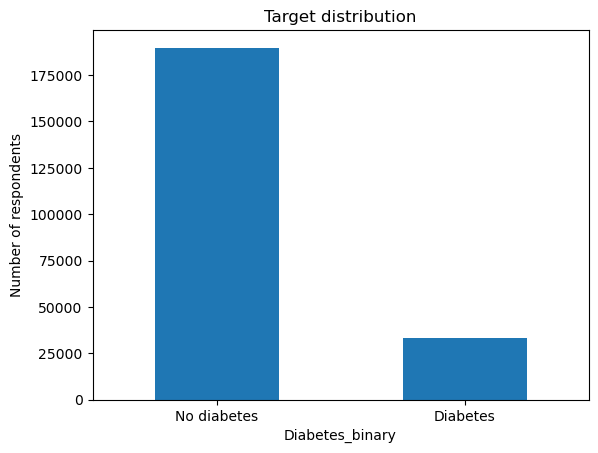

In [5]:
# Target balance
y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["No diabetes", "Diabetes"], rotation=0)
plt.ylabel("Number of respondents")
plt.title("Target distribution")
plt.show()

Imbalanced (85% / 15%), so accuracy is misleading. The training data is balanced in section 8.

## 4. Univariate analysis

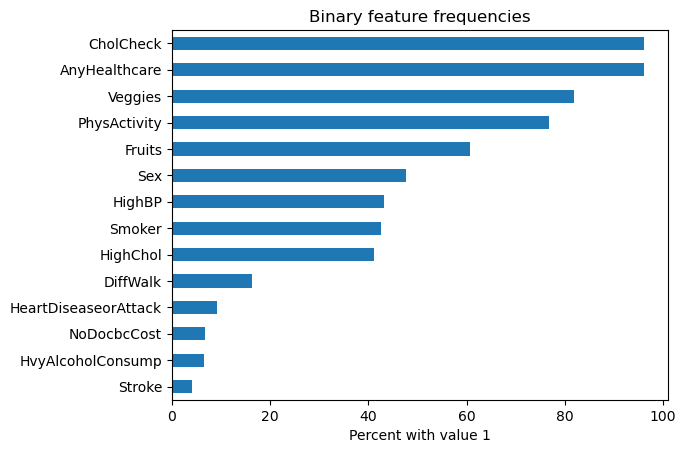

In [6]:
# Percentage of respondents with value 1 for binary features
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]
(df[binary_features].mean().sort_values() * 100).plot(kind="barh")
plt.xlabel("Percent with value 1")
plt.title("Binary feature frequencies")
plt.show()

Near-constant: CholCheck and AnyHealthcare (96% = 1), Stroke (4%), HvyAlcoholConsump (6%).

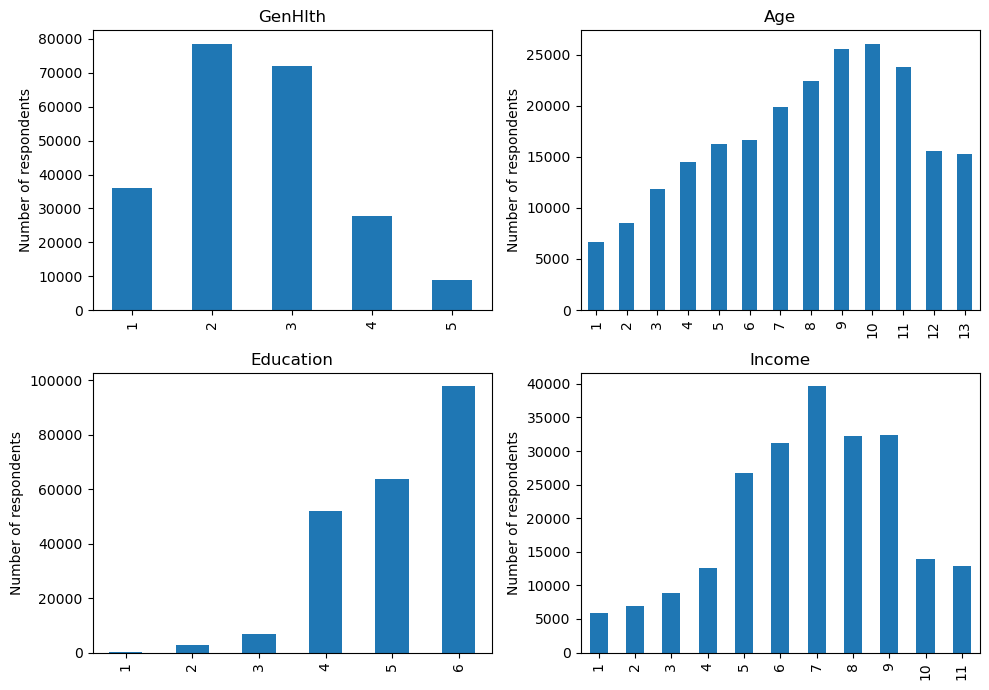

In [7]:
# Distribution of ordinal features
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ordinal_features):
    df[col].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Number of respondents")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Mostly older (Age 8–11 = 55–74), well-educated respondents. Income peaks at level 7 ($50–75k).

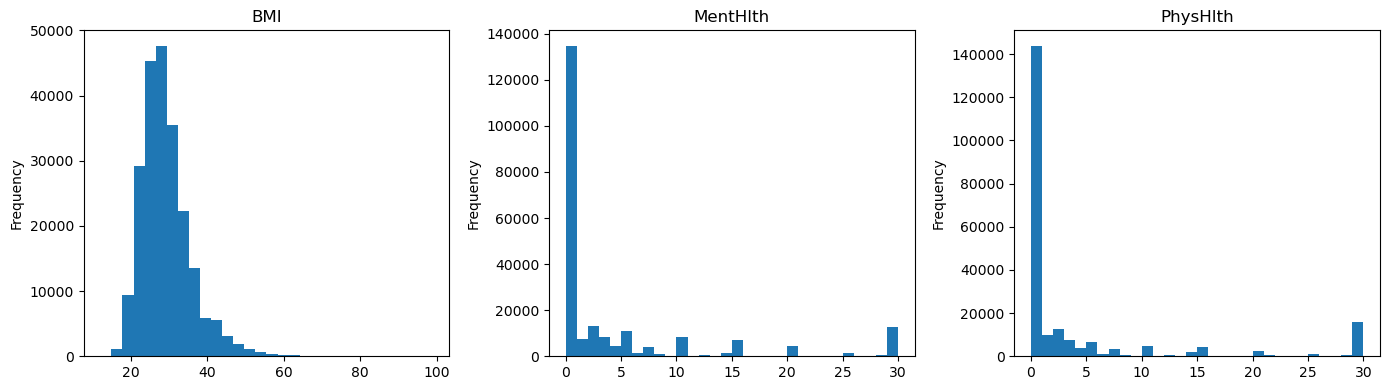

In [8]:
# Distribution of BMI and poor-health days
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    df[col].plot(kind="hist", bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

BMI is right-skewed (median 28). Values above 70 (124 rows) are kept, because trees are not affected by outliers. Most people report 0 poor-health days.

## 5. Bivariate analysis (feature vs. target)

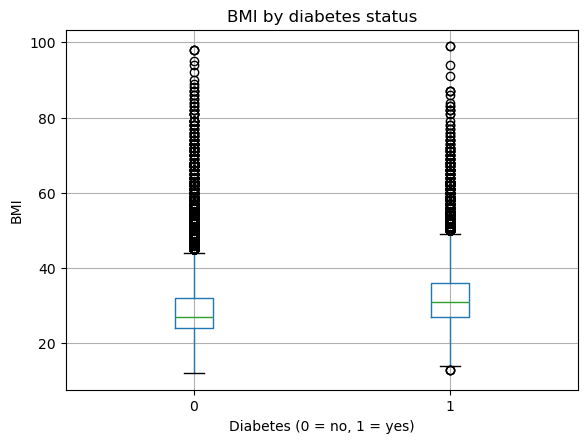

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0,189848.0,28.6,6.4,12.0,24.0,27.0,32.0,98.0
1,33395.0,32.2,7.4,13.0,27.0,31.0,36.0,99.0


In [9]:
# BMI distribution by target
df.boxplot(column="BMI", by=TARGET)
plt.xlabel("Diabetes (0 = no, 1 = yes)")
plt.ylabel("BMI")
plt.title("BMI by diabetes status")
plt.suptitle("")
plt.show()

display(df.groupby(TARGET)["BMI"].describe().round(1))

People with diabetes have a higher BMI (median 31 vs. 27).

BMI_category
Underweight     6.04
Normal          6.85
Overweight     12.41
Obesity I      18.75
Obesity II     24.16
Obesity III    30.31
Name: diabetes_rate_%, dtype: float64

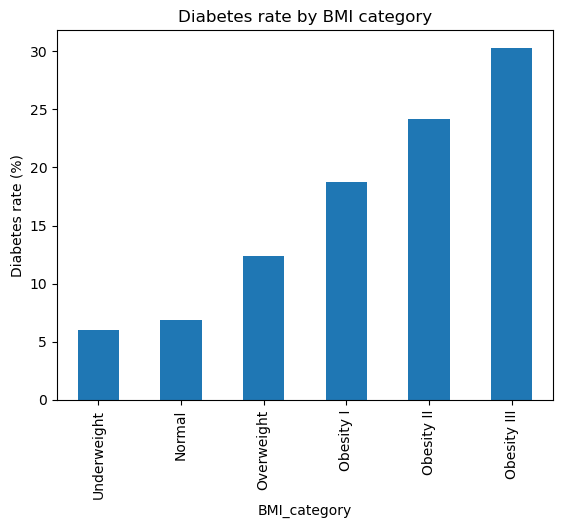

In [10]:
# BMI category and diabetes rate
df["BMI_category"] = pd.cut(
    df["BMI"], bins=[0, 18.5, 25, 30, 35, 40, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obesity I", "Obesity II", "Obesity III"],
    right=False
)
display((df.groupby("BMI_category", observed=True)[TARGET].mean() * 100).rename("diabetes_rate_%").round(2))
(df.groupby("BMI_category", observed=True)[TARGET].mean() * 100).plot(kind="bar")
plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate by BMI category")
plt.show()

The rate rises from about 7% (normal) to 30% (obesity III).

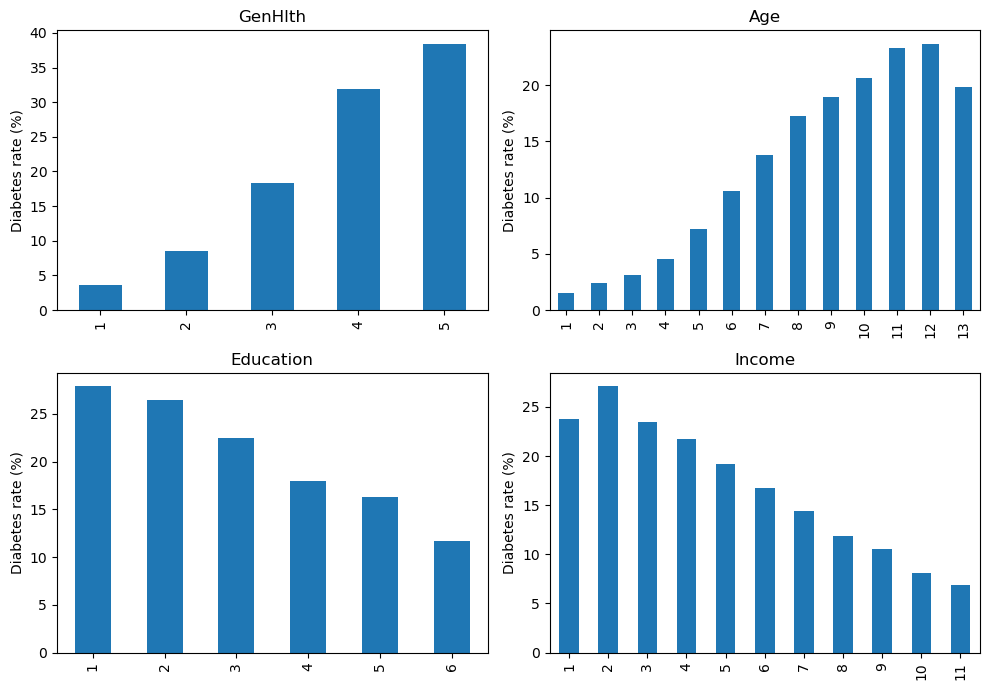

In [11]:
# Diabetes rate by each ordinal feature
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ordinal_features):
    (df.groupby(col, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Diabetes rate (%)")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

- The rate rises with worse general health (4% → 38%) and with age (peak 24% at 75–79).
- It falls with education (28% → 12%) and income (27% → 7%).

,rate_when_0_%,rate_when_1_%
feature,,
HeartDiseaseorAttack,13.03,34.21
Stroke,14.23,31.82
DiffWalk,11.77,31.37
HighBP,7.01,25.43
HighChol,9.17,23.26
Smoker,13.51,16.91
Sex,13.71,16.34
NoDocbcCost,14.88,15.99
CholCheck,1.94,15.48


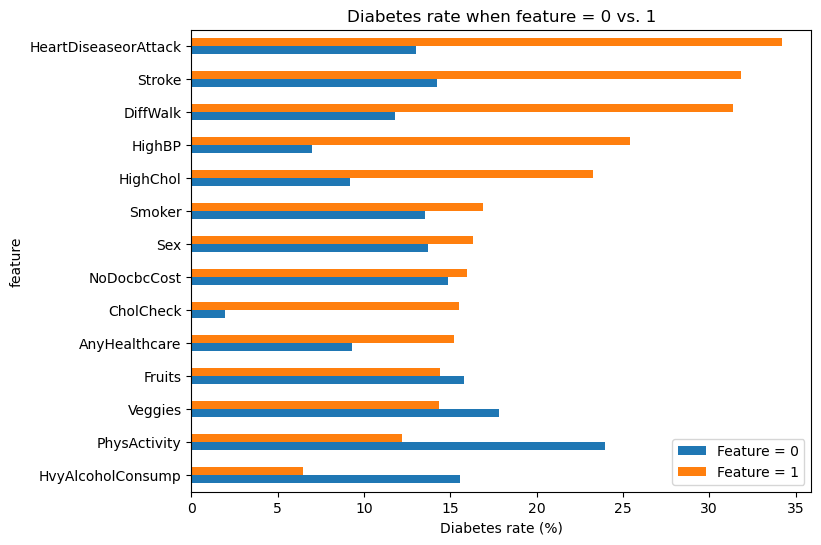

In [12]:
# Diabetes rate for feature values 0 and 1
rows = []
for col in binary_features:
    rates = df.groupby(col)[TARGET].mean()
    rows.append({
        "feature": col,
        "rate_when_0_%": rates.get(0, np.nan) * 100,
        "rate_when_1_%": rates.get(1, np.nan) * 100
    })

binary_rates = pd.DataFrame(rows).set_index("feature")
display(binary_rates.round(2).sort_values("rate_when_1_%", ascending=False))

binary_rates.sort_values("rate_when_1_%").plot(kind="barh", figsize=(8, 6))
plt.xlabel("Diabetes rate (%)")
plt.title("Diabetes rate when feature = 0 vs. 1")
plt.legend(["Feature = 0", "Feature = 1"])
plt.show()

- Strongest: HeartDiseaseorAttack, Stroke, DiffWalk, HighBP, HighChol (2.2–3.6× higher rate when = 1).
- PhysActivity and HvyAlcoholConsump go with lower rates.

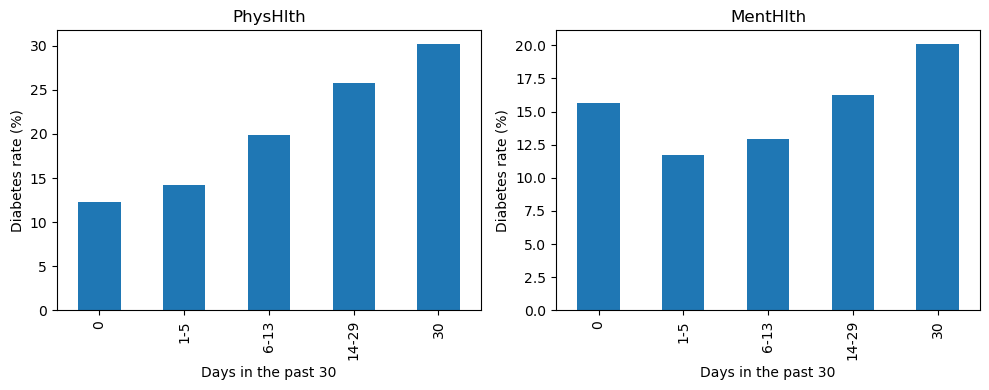

In [13]:
# Diabetes rate by number of poor-health days
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["PhysHlth", "MentHlth"]):
    days = pd.cut(df[col], bins=[-1, 0, 5, 13, 29, 30], labels=["0", "1-5", "6-13", "14-29", "30"])
    (df.groupby(days, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Days in the past 30")
    ax.set_ylabel("Diabetes rate (%)")
plt.tight_layout()
plt.show()

PhysHlth matters (12% → 30%). MentHlth is weak and not steady.

## 6. Correlation

GenHlth                 0.265
HighBP                  0.256
DiffWalk                0.203
HighChol                0.194
BMI                     0.193
Age                     0.192
HeartDiseaseorAttack    0.171
Income                 -0.139
PhysActivity           -0.139
PhysHlth                0.128
Stroke                  0.098
Education              -0.089
CholCheck               0.073
HvyAlcoholConsump      -0.063
Smoker                  0.047
Veggies                -0.038
Sex                     0.037
AnyHealthcare           0.032
Fruits                 -0.019
MentHlth               -0.009
NoDocbcCost             0.008
Name: Diabetes_binary, dtype: float64

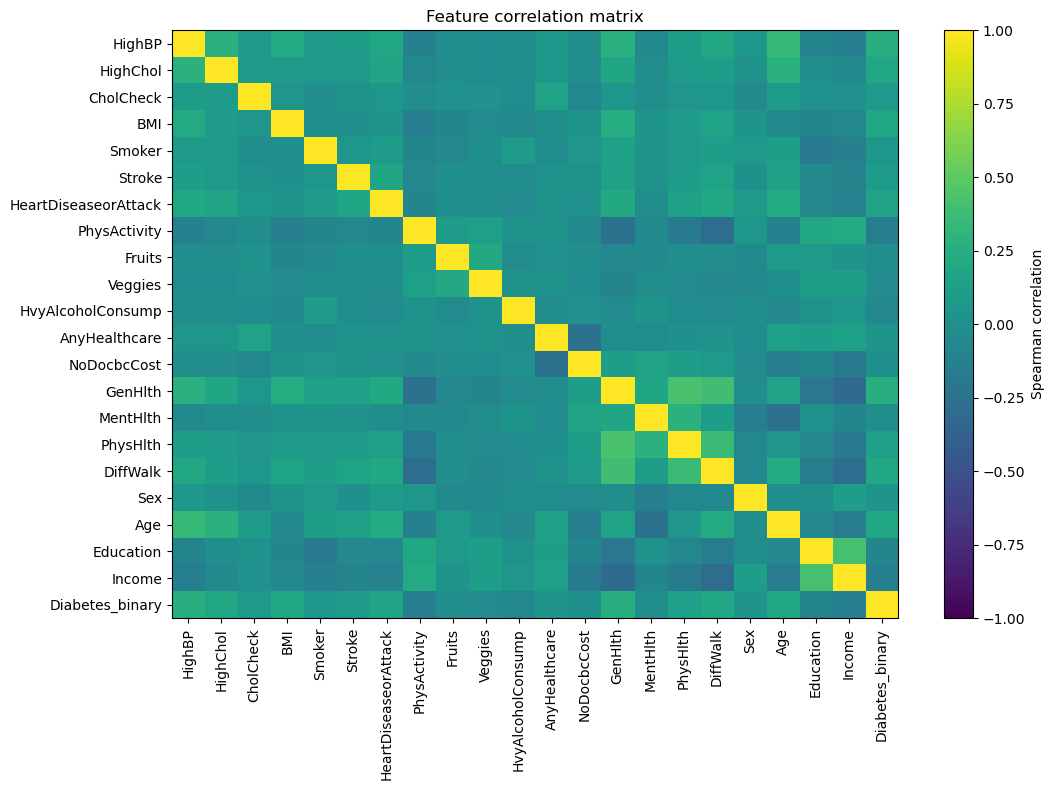

In [14]:
# Spearman correlations
corr = df[FEATURES + [TARGET]].corr(method="spearman")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(11, 8))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

Correlations with the target are modest (max 0.265, GenHlth and HighBP). No feature pair is above 0.42, so there's no multicollinearity.

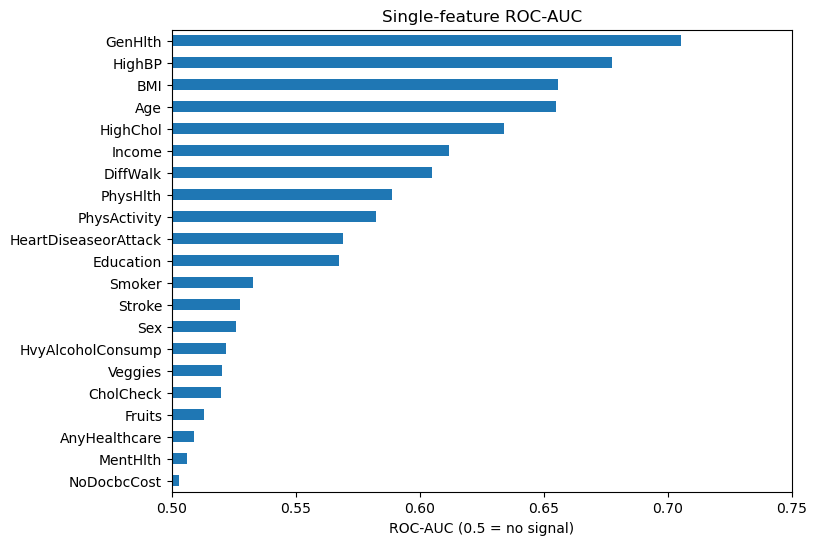

In [15]:
# Leakage check: ROC-AUC of each feature on its own
auc = pd.Series({c: roc_auc_score(df[TARGET], df[c]) for c in FEATURES})
auc = np.maximum(auc, 1 - auc).sort_values()   # strength in either direction
auc.plot(kind="barh", figsize=(8, 6), xlim=(0.5, 0.75))
plt.xlabel("ROC-AUC (0.5 = no signal)")
plt.title("Single-feature ROC-AUC")
plt.show()

The best single feature (GenHlth) reaches only 0.70, so there's no leakage.

## 7. Multivariate analysis

,count,diabetes_rate
condition_count,,
0,86010,4.61
1,73357,13.48
2,49209,27.80
3,12825,38.85
4,1842,47.88


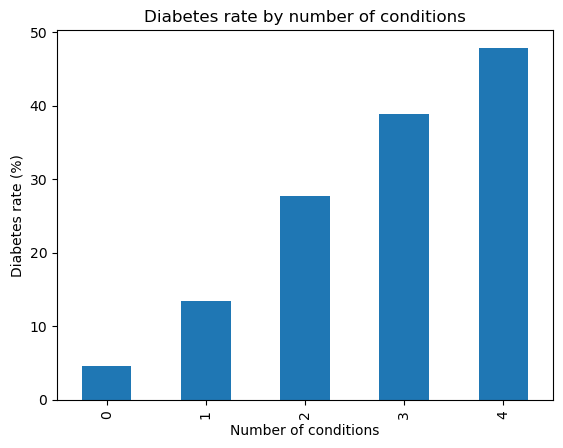

In [16]:
# Number of cardiometabolic conditions
conditions = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]
df["condition_count"] = df[conditions].sum(axis=1)
display(df.groupby("condition_count")[TARGET].agg(["count", "mean"]).rename(columns={"mean": "diabetes_rate"}).assign(
    diabetes_rate=lambda x: (x["diabetes_rate"] * 100).round(2)
))
(df.groupby("condition_count")[TARGET].mean() * 100).plot(kind="bar")
plt.xlabel("Number of conditions")
plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate by number of conditions")
plt.show()

The rate rises with each extra condition: 5% (none) → 48% (all four).

BMI_category,Underweight,Normal,Overweight,Obesity I,Obesity II,Obesity III
Age,,,,,,
18-39,1.3,1.3,1.8,3.7,6.0,11.3
40-49,5.1,3.2,5.3,10.4,14.6,22.9
50-59,7.6,6.3,11.1,18.0,25.5,34.0
60-69,8.0,8.5,15.7,24.5,32.2,42.1
70+,7.9,12.2,20.6,29.5,38.5,45.0


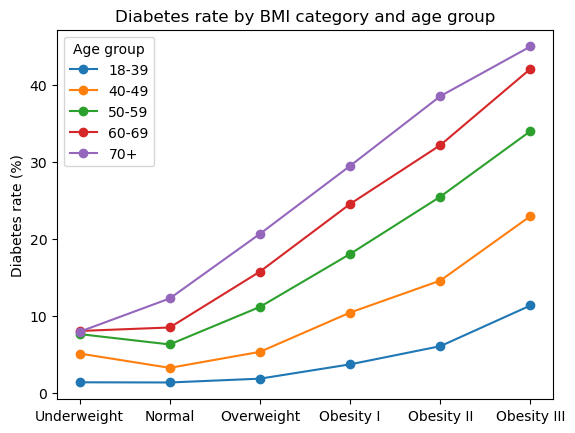

In [17]:
# Age group x BMI category
age_group = pd.cut(df["Age"], bins=[0, 4, 6, 8, 10, 13], labels=["18-39", "40-49", "50-59", "60-69", "70+"])
age_bmi = pd.crosstab(age_group, df["BMI_category"], values=df[TARGET], aggfunc="mean") * 100
display(age_bmi.round(1))

age_bmi.T.plot(marker="o")
plt.ylabel("Diabetes rate (%)")
plt.xlabel("")
plt.title("Diabetes rate by BMI category and age group")
plt.legend(title="Age group")
plt.show()

Age and BMI add up: about 1% (18–39, normal BMI) → 45% (70+, obesity III).

## 8. Balance the dataset
- Split first (80/20, stratified).
- Then undersample the training set: keep all diabetes rows and the same number of random no-diabetes rows.
- The test set keeps the real 85/15 ratio, so test scores stay honest.

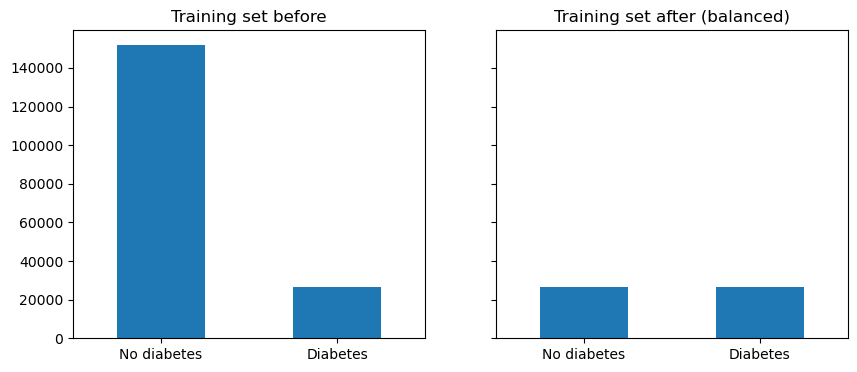

Train before: {0: 151878, 1: 26716}
Train after:  {0: 26716, 1: 26716}
Test (unchanged): {0: 37970, 1: 6679}


In [18]:
# Split (original 21 features only)
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Random undersampling of the training set
train = pd.concat([X_train, y_train], axis=1)
n_diabetes = (train[TARGET] == 1).sum()
train_bal = pd.concat([
    train[train[TARGET] == 1],
    train[train[TARGET] == 0].sample(n_diabetes, random_state=RANDOM_STATE)
]).sample(frac=1, random_state=RANDOM_STATE)   # shuffle
X_train_bal, y_train_bal = train_bal[FEATURES], train_bal[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
y_train.value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Training set before")
y_train_bal.value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Training set after (balanced)")
for ax in axes:
    ax.set_xticks([0, 1], ["No diabetes", "Diabetes"], rotation=0)
    ax.set_xlabel("")
plt.show()

print("Train before:", y_train.value_counts().to_dict())
print("Train after: ", y_train_bal.value_counts().to_dict())
print("Test (unchanged):", y_test.value_counts().to_dict())

## 9. Modelling
Each model gets a 5-fold CV ROC-AUC on its training data and is then scored on the real test set (threshold 0.5).

In [19]:
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, ConfusionMatrixDisplay)

results = {}   # name -> scores
probas = {}    # name -> predicted probabilities on the test set

def evaluate(name, model, X_tr, y_tr):
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=5, scoring="roc_auc").mean()
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = {
        "CV ROC-AUC": cv_auc,
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    }
    probas[name] = proba
    return pd.DataFrame(results).T.round(3)

### 9.1 XGBoost on the original (imbalanced) data
For comparison only: this shows why balancing is needed.

In [20]:
evaluate("XGBoost - imbalanced", xgb.XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train, y_train)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.81,0.409,0.16,0.532,0.246,0.853


High accuracy (85%), but recall is only 16%: it misses most diabetics.

### 9.2 XGBoost on the balanced data

In [21]:
evaluate("XGBoost - balanced", xgb.XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702


Recall jumps to 78% and F1 from 0.25 to 0.44. Precision drops, as expected.

### 9.3 XGBoost, balanced + better settings
Slower learning, smaller trees and subsampling, to reduce overfitting.

In [22]:
xgb_model = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              subsample=0.8, colsample_bytree=0.8,
                              random_state=RANDOM_STATE, n_jobs=-1)
evaluate("XGBoost - balanced + settings", xgb_model, X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703


Best model: ROC-AUC rises from 0.806 to 0.814, and PR-AUC from 0.402 to 0.420.

### 9.4 Comparison model: Logistic Regression
A simple linear baseline (scaled features), trained on the same balanced data.

In [23]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
evaluate("Logistic Regression - balanced", log_reg, X_train_bal, y_train_bal)

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716


## 10. Results

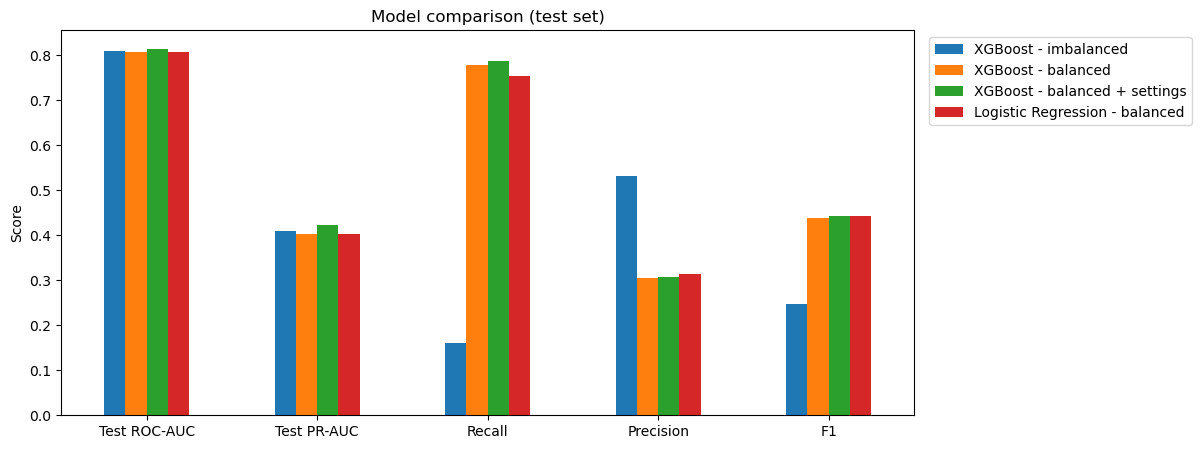

In [24]:
# Compare the models on the test set
metrics = ["Test ROC-AUC", "Test PR-AUC", "Recall", "Precision", "F1"]
pd.DataFrame(results).loc[metrics].plot(kind="bar", figsize=(11, 5))
plt.xticks(rotation=0)
plt.ylabel("Score")
plt.title("Model comparison (test set)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

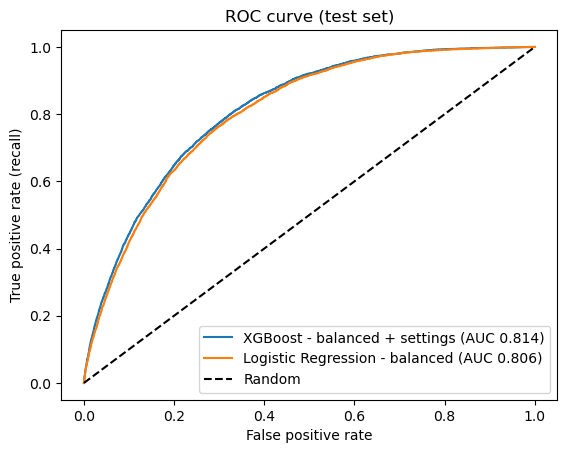

In [25]:
# ROC curves: best XGBoost vs. Logistic Regression
for name in ["XGBoost - balanced + settings", "Logistic Regression - balanced"]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC {results[name]['Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

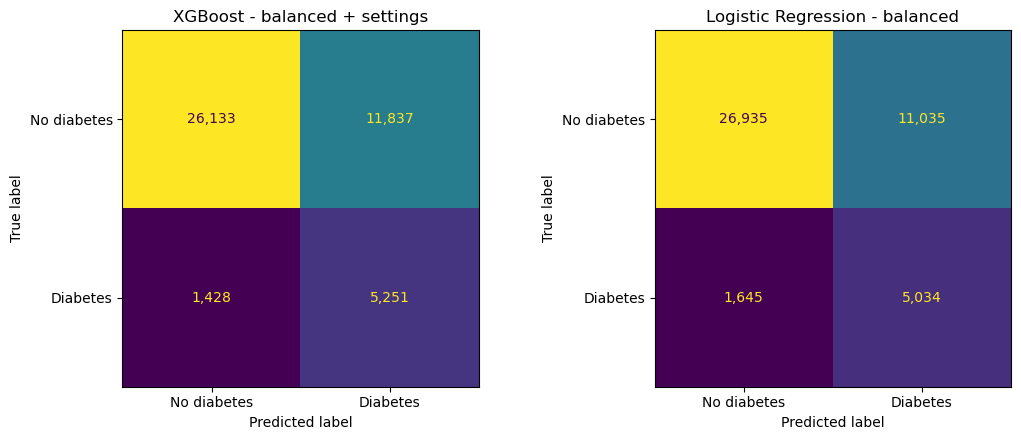

In [26]:
# Confusion matrices (test set)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["XGBoost - balanced + settings", "Logistic Regression - balanced"]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probas[name] >= 0.5).astype(int),
                                            display_labels=["No diabetes", "Diabetes"],
                                            ax=ax, colorbar=False, values_format=",")
    ax.set_title(name)
plt.tight_layout()
plt.show()

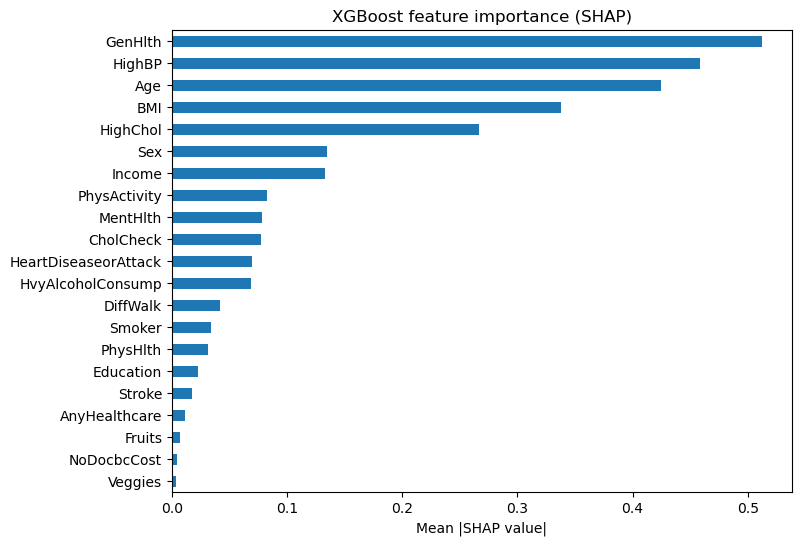

In [27]:
# Feature importance (best XGBoost): mean |SHAP value| on the test set
shap_values = xgb_model.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]   # last column = bias
pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Mean |SHAP value|")
plt.title("XGBoost feature importance (SHAP)")
plt.show()

## 11. Conclusion
- Balancing the training data was the biggest improvement: recall went from 16% to 78%.
- Best model: XGBoost (balanced + settings). Test ROC-AUC 0.814, PR-AUC 0.420, recall 79%, F1 0.44.
- Logistic Regression is close: same F1 (0.44), but lower ROC-AUC (0.806), PR-AUC (0.402) and recall (75%).
- Top features (SHAP): GenHlth, HighBP, Age, BMI, HighChol.

## Gradient Boosting Classifier

In [28]:
from sklearn.ensemble import GradientBoostingClassifier

gb_imbalanced = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

evaluate(
    "Gradient Boosting - imbalanced",
    gb_imbalanced,
    X_train,
    y_train
)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855


The Gradient Boosting model achieved 85.5% accuracy, but the recall was only 15.8%. This means the model missed most diabetes cases. The results show that high accuracy does not always mean the model performs well.

In [29]:
gb_balanced = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

evaluate(
    "Gradient Boosting - balanced",
    gb_balanced,
    X_train_bal,
    y_train_bal
)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703


Using balanced data improved the model's recall from 15.8% to 78.1%, helping it detect more diabetes cases. However, precision decreased to 30.7%, meaning the model made more false positive predictions.

In [30]:
gb_tuned = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=RANDOM_STATE
)

evaluate(
    "Gradient Boosting - balanced + settings",
    gb_tuned,
    X_train_bal,
    y_train_bal
)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703




Changing the model settings slightly improved recall from 78.1% to 78.5%. However, the F1 score stayed the same at 0.441, so the improvement was very small.

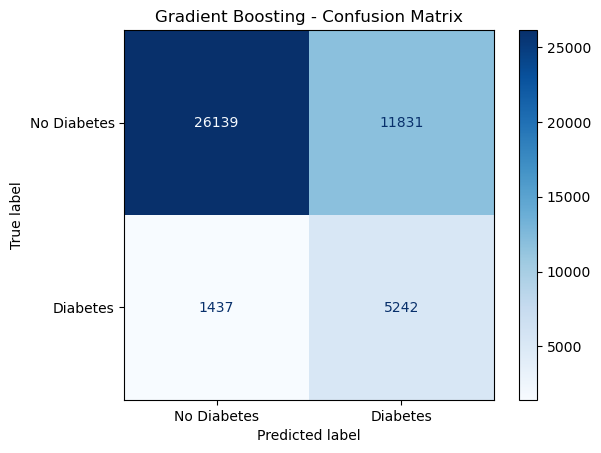

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

gb_predictions = (probas["Gradient Boosting - balanced + settings"] >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

The model correctly detected 5,242 diabetes cases but missed 1,437 cases. It achieved 78.5% recall, but also made many false positive predictions.

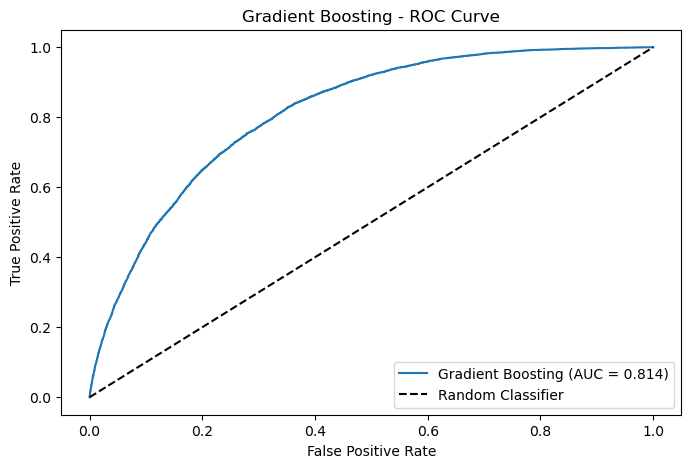

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

gb_probs = probas["Gradient Boosting - balanced + settings"]

fpr, tpr, thresholds = roc_curve(y_test, gb_probs)
auc_score = roc_auc_score(y_test, gb_probs)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting - ROC Curve")
plt.legend()
plt.show()

The Gradient Boosting model achieved a ROC-AUC of 0.814, showing good ability to distinguish between people with and without diabetes. The model performed better than random guessing.

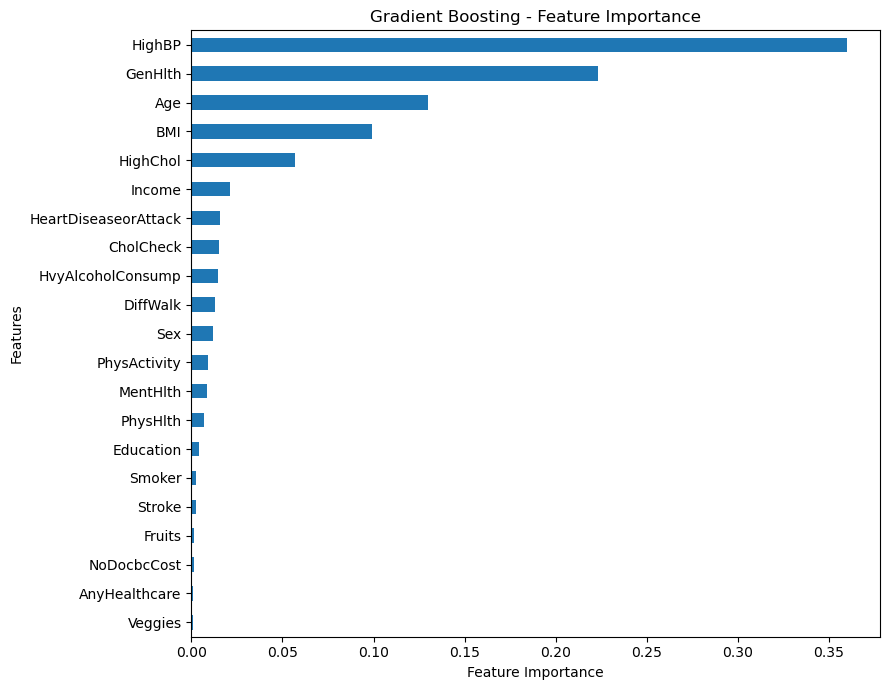

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

gb_importance = pd.Series(
    gb_tuned.feature_importances_,
    index=X_train_bal.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 7))

gb_importance.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Gradient Boosting - Feature Importance")

plt.tight_layout()
plt.show()

The most important features were HighBP, GenHlth, Age, BMI, and HighChol. HighBP had the highest importance, meaning the model relied on it the most when making predictions.

In [34]:
import pandas as pd

# Gradient Boosting experiments
gb_names = [
    "Gradient Boosting - imbalanced",
    "Gradient Boosting - balanced",
    "Gradient Boosting - balanced + settings"
]

# Create comparison table
gb_comparison = pd.DataFrame(results).T

# Select Gradient Boosting experiments
gb_comparison = gb_comparison.reindex(gb_names)

# Display results
display(gb_comparison.round(3))

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703


Balancing the training data improved the model's recall from 15.8% to 78.1%. Changing the settings increased recall slightly to 78.5%, but the F1 score stayed the same at 0.441. The tuned balanced model detected the most diabetes cases, but it still produced many false positives.

# 10. Logistic Regression

Logistic Regression is a classification model used to predict diabetes.

We used the same training and testing data to compare its performance with the other models.

## 10.1 Baseline Logistic Regression

We first trained Logistic Regression on the original training data without balancing.

StandardScaler was used to scale the features before training.

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr_base = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

evaluate("Logistic Regression - imbalanced",
         lr_base, X_train, y_train)

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703
Logistic Regression - imbalanced,0.807,0.806,0.403,0.149,0.532,0.232,0.853


## 10.2 Logistic Regression with Balanced Data

We trained Logistic Regression using the balanced training data to improve the detection of diabetes cases.

The test data remained unchanged.

In [36]:
lr_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

evaluate("Logistic Regression - balanced",
         lr_balanced, X_train_bal, y_train_bal)

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703
Logistic Regression - imbalanced,0.807,0.806,0.403,0.149,0.532,0.232,0.853


## 10.3 Logistic Regression Results

We compared the model performance before and after balancing the training data.

We focused on Recall, Precision, F1-Score, and ROC-AUC.

In [37]:
lr_names = [
    "Logistic Regression - imbalanced",
    "Logistic Regression - balanced"
]

lr_results = pd.DataFrame(results).T.loc[lr_names]

display(lr_results.round(3))

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
Logistic Regression - imbalanced,0.807,0.806,0.403,0.149,0.532,0.232,0.853
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716


## 10.4 Performance Comparison

We used a bar chart to compare the results before and after balancing.

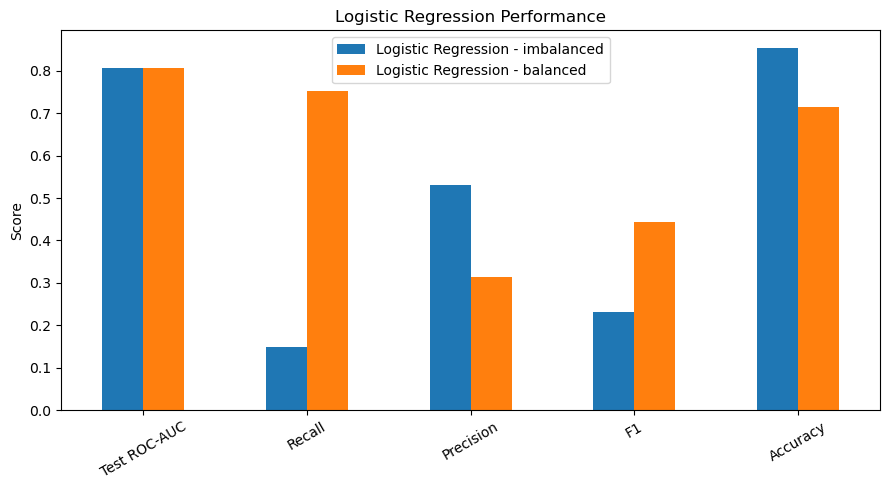

In [38]:
lr_results[
    ["Test ROC-AUC", "Recall", "Precision", "F1", "Accuracy"]
].T.plot(kind="bar", figsize=(9, 5))

plt.title("Logistic Regression Performance")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

## 10.5 Confusion Matrix

We used confusion matrices to compare the prediction errors before and after balancing.

We focused on false negatives because they represent missed diabetes cases.

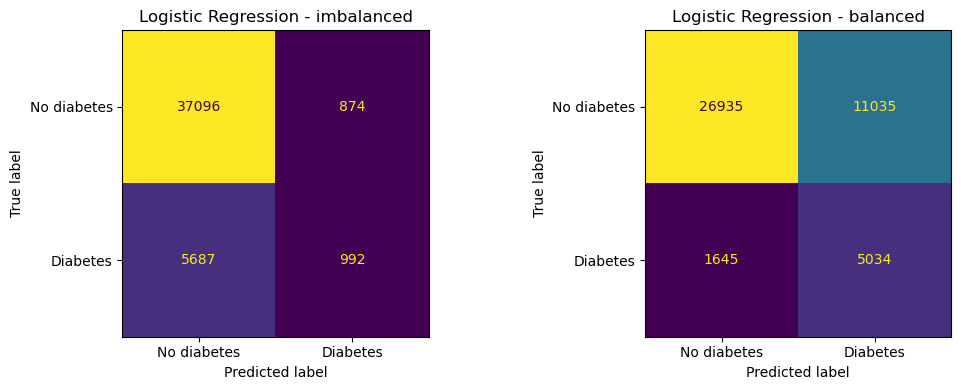

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name in zip(axes, lr_names):
    pred = (probas[name] >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=["No diabetes", "Diabetes"],
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

#11 Model Comparison

# 11. Model Comparison

We compared XGBoost, Gradient Boosting and Logistic Regression to see which model performs better in predicting diabetes.



## 11.1 Model Performance Comparison

All three models were evaluated using the same test data.

We compared Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

In [40]:
models = [
    "XGBoost - balanced + settings",
    "Gradient Boosting - balanced",
    "Logistic Regression - balanced"
]

comparison = pd.DataFrame(results).T.loc[models]

display(comparison.round(3))

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716


## 11.2 Performance Visualization

We used a bar chart to make the comparison easier and see the differences between the three models.

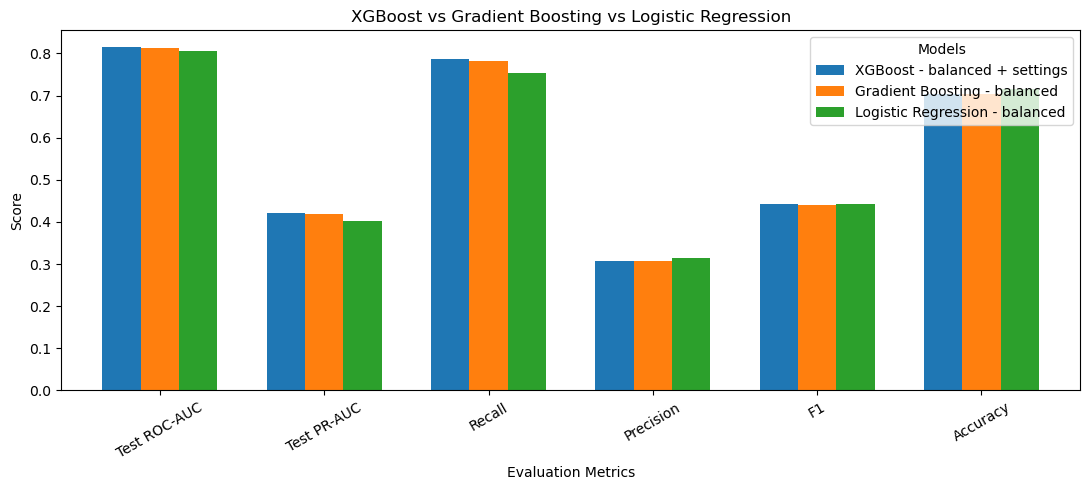

In [41]:
metrics = [
    "Test ROC-AUC",
    "Test PR-AUC",
    "Recall",
    "Precision",
    "F1",
    "Accuracy"
]

comparison[metrics].T.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.7
)

plt.title("XGBoost vs Gradient Boosting vs Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=30)
plt.legend(title="Models")
plt.tight_layout()
plt.show()

## 11.3 ROC Curve Comparison

We compared the ROC curves to see how well each model separates diabetic and non-diabetic cases.

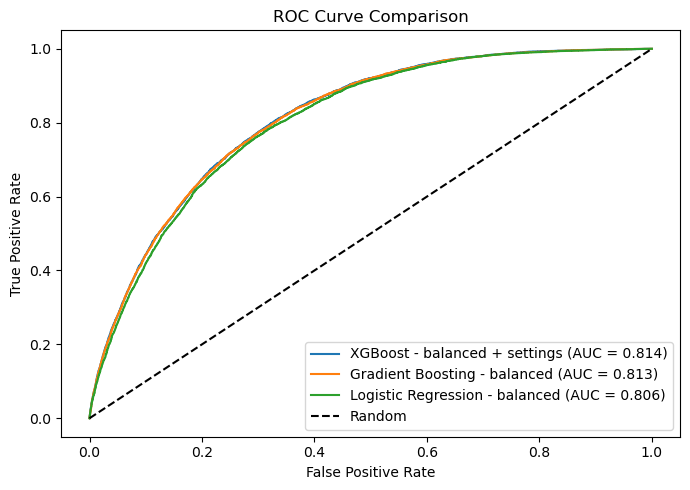

In [42]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 5))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    auc = roc_auc_score(y_test, probas[name])

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

## 11.4 Confusion Matrix Comparison

We compared the confusion matrices to check the prediction errors of the three models.

We focused on false negatives because they represent diabetes cases that the models failed to detect.

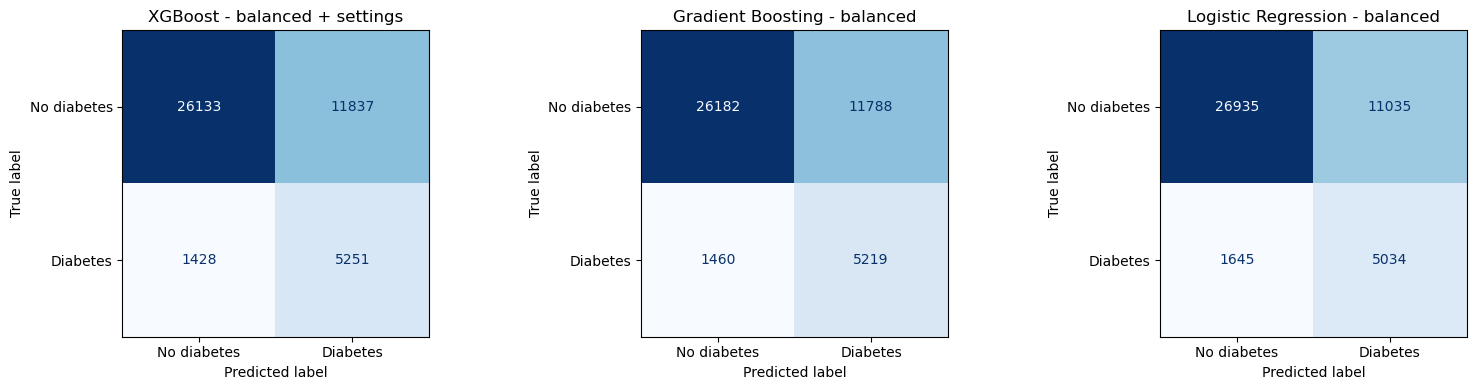

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, name in zip(axes, models):

    pred = (probas[name] >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=["No diabetes", "Diabetes"],
        ax=ax,
        colorbar=False,
        cmap="Blues"
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

## 11.5 Final Model Selection

After comparing the three models, we focused on Recall and F1-Score because detecting diabetes cases is important in our project.

We also considered ROC-AUC, PR-AUC, and Precision before selecting the final model.

In [44]:
selection = comparison[
    ["Recall", "Precision", "F1", "Test ROC-AUC", "Test PR-AUC"]
]

display(selection.round(3))

print("Higher Recall:", selection["Recall"].idxmax())
print("Higher F1:", selection["F1"].idxmax())
print("Higher ROC-AUC:", selection["Test ROC-AUC"].idxmax())
print("Higher PR-AUC:", selection["Test PR-AUC"].idxmax())

,Recall,Precision,F1,Test ROC-AUC,Test PR-AUC
XGBoost - balanced + settings,0.786,0.307,0.442,0.814,0.421
Gradient Boosting - balanced,0.781,0.307,0.441,0.813,0.419
Logistic Regression - balanced,0.754,0.313,0.443,0.806,0.402


Higher Recall: XGBoost - balanced + settings
Higher F1: Logistic Regression - balanced
Higher ROC-AUC: XGBoost - balanced + settings
Higher PR-AUC: XGBoost - balanced + settings


## 11.6 Tuned Cut-off

All models above use a cut-off of 0.5. They were trained on balanced (50/50) data, so 0.5 flags too many people.

We picked a better cut-off for each model on a validation set taken from the training data (real 85/15 ratio), then checked it once on the test set.

In [45]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

# validation set from the training data, keeps the real 85/15 ratio
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

# undersample the fitting part the same way as before
fit = pd.concat([X_fit, y_fit], axis=1)
n_diabetes_fit = (fit[TARGET] == 1).sum()
fit_bal = pd.concat([
    fit[fit[TARGET] == 1],
    fit[fit[TARGET] == 0].sample(n_diabetes_fit, random_state=RANDOM_STATE)
]).sample(frac=1, random_state=RANDOM_STATE)

final_models = {
    "XGBoost - balanced + settings": xgb_model,
    "Gradient Boosting - balanced": gb_balanced,
    "Logistic Regression - balanced": lr_balanced
}

tuned = {}

for name, model in final_models.items():

    # train a copy on the balanced part, then take the cut-off with the best F1 on validation
    m = clone(model).fit(fit_bal[FEATURES], fit_bal[TARGET])
    precision, recall, cuts = precision_recall_curve(y_val, m.predict_proba(X_val)[:, 1])
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    cut = cuts[np.argmax(f1[:-1])]

    # check the tuned cut-off once on the test set
    pred = (probas[name] >= cut).astype(int)

    tuned[name] = {
        "Cut-off": cut,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Test ROC-AUC": results[name]["Test ROC-AUC"],
        "Test PR-AUC": results[name]["Test PR-AUC"]
    }

tuned = pd.DataFrame(tuned).T

display(tuned.round(3))

print("Higher F1:", tuned["F1"].idxmax())
print("Higher ROC-AUC:", tuned["Test ROC-AUC"].idxmax())

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

,Cut-off,Recall,Precision,F1,Test ROC-AUC,Test PR-AUC
XGBoost - balanced + settings,0.624,0.637,0.366,0.464,0.814,0.421
Gradient Boosting - balanced,0.605,0.657,0.358,0.464,0.813,0.419
Logistic Regression - balanced,0.567,0.675,0.342,0.454,0.806,0.402


Higher F1: XGBoost - balanced + settings
Higher ROC-AUC: XGBoost - balanced + settings


## 11.7 Conclusion

- At the 0.5 cut-off, Logistic Regression has a slightly higher F1 (0.443 vs. 0.442), but XGBoost has the highest Recall (0.786), ROC-AUC (0.814) and PR-AUC (0.421).
- With a tuned cut-off, XGBoost and Gradient Boosting reach the best F1 (0.464). Logistic Regression is lower (0.454): it finds more diabetes cases (Recall 0.675), but it makes more false positive predictions (Precision 0.342).
- We selected XGBoost as the final model: it ranks people best (highest ROC-AUC and PR-AUC) and has the best F1 with a tuned cut-off.